<a href="https://colab.research.google.com/github/priyasathe123/ML-Practical-s/blob/main/Basic_Perceptron_MLP_Activation_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment: Perceptron and Multilayer Perceptron (MLP)



## Aim
1. Implement a single-layer perceptron from scratch.
2. Train a Multilayer Perceptron (MLP) using Scikit-learn.
3. Compare different activation functions.


**Author: Dr. Priya B. Pandharbale**

**Libraries:** NumPy, Matplotlib and Scikit-learn

Run the cells one by one in Google Colab or Jupyter Notebook.

## Part A: Single-Layer Perceptron from Scratch

### 1. Import libraries and create simple data

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Simple linearly separable data (two input features)
X = np.array([
    [1, 1],
    [2, 1],
    [1, 2],
    [4, 4],
    [5, 4],
    [4, 5]
])

y = np.array([0, 0, 0, 1, 1, 1])

print("Input data:")
print(X)
print("Target values:", y)

Input data:
[[1 1]
 [2 1]
 [1 2]
 [4 4]
 [5 4]
 [4 5]]
Target values: [0 0 0 1 1 1]


### 2. Implement the Perceptron algorithm

In [2]:
# Initialize weights and bias
weights = np.zeros(2)
bias = 0
learning_rate = 0.1
epochs = 10

# Train the perceptron
for epoch in range(epochs):
    for i in range(len(X)):
        # Calculate weighted sum
        total = np.dot(X[i], weights) + bias

        # Step activation function
        prediction = 1 if total >= 0 else 0

        # Calculate error and update weights
        error = y[i] - prediction
        weights = weights + learning_rate * error * X[i]
        bias = bias + learning_rate * error

print("Final weights:", weights)
print("Final bias:", bias)

Final weights: [2.77555756e-17 1.00000000e-01]
Final bias: -0.4


### 3. Test the Perceptron

In [3]:
# Predict output for all input samples
predictions = []

for sample in X:
    total = np.dot(sample, weights) + bias
    prediction = 1 if total >= 0 else 0
    predictions.append(prediction)

print("Actual values:   ", y)
print("Predicted values:", predictions)

Actual values:    [0 0 0 1 1 1]
Predicted values: [0, 0, 0, 1, 1, 1]


## Part B: Multilayer Perceptron using Scikit-learn

### 4. Load a sample dataset

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Use two Iris classes for a simple binary classification problem
iris = load_iris()
X = iris.data[:100, :2]
y = iris.target[:100]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 80
Testing samples: 20


### 5. Train an MLP model

In [5]:
# Train MLP with ReLU activation
mlp = MLPClassifier(
    hidden_layer_sizes=(5,),
    activation="relu",
    max_iter=1000,
    random_state=42
)

mlp.fit(X_train, y_train)

y_pred = mlp.predict(X_test)

print("Actual values:   ", y_test)
print("Predicted values:", y_pred)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Actual values:    [1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0]
Predicted values: [1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0]
Accuracy: 100.0 %


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


### 6. Compare different activation functions

We train the same MLP using ReLU, tanh and logistic (sigmoid) activation functions and compare their test accuracy.

In [6]:
activation_functions = ["relu", "tanh", "logistic"]
results = []

for activation in activation_functions:
    model = MLPClassifier(
        hidden_layer_sizes=(5,),
        activation=activation,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    accuracy = accuracy_score(y_test, prediction)

    results.append(accuracy)
    print(activation, "Accuracy:", round(accuracy * 100, 2), "%")

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


relu Accuracy: 100.0 %


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


tanh Accuracy: 100.0 %
logistic Accuracy: 100.0 %


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


### 7. Plot activation function comparison

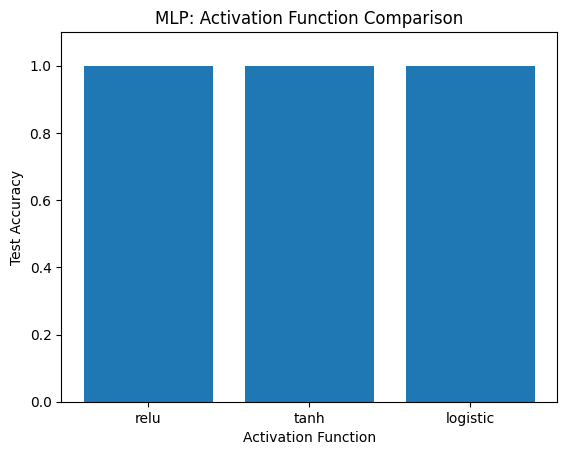

In [7]:
plt.bar(activation_functions, results)
plt.xlabel("Activation Function")
plt.ylabel("Test Accuracy")
plt.title("MLP: Activation Function Comparison")
plt.ylim(0, 1.1)
plt.show()

## Observations
1. A single-layer perceptron uses weights, bias and a step activation function.
2. During training, weights and bias are updated using the prediction error.
3. An MLP contains an input layer, one or more hidden layers and an output layer.
4. ReLU, tanh and logistic are commonly used activation functions.
5. The accuracy may differ depending on the activation function and training settings.

## Result
A single-layer perceptron was implemented from scratch. An MLP was trained using Scikit-learn, and the test accuracy of ReLU, tanh and logistic activation functions was compared.